# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/surajprai2111-ui/ML-assignment/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Abstract

This project examines whether anonymized content-performance data can help content teams prioritize pages for human review. I compared a rule-based scoring baseline with a Random Forest classifier using a target derived from the existing `trend_direction` label. To evaluate performance on unseen clients, I used a client-grouped train-test split, with 25 clients in training and 7 in testing, and no client overlap. On the held-out test set, the Random Forest achieved an Average Precision of 0.5894, compared with 0.5008 for the rule-based baseline, an absolute improvement of 0.0886. These results suggest that the model may help rank pages with an observed declining trend for further investigation. However, the target represents an existing trend rather than future decline, and further validation is needed before practical use. The model should support human decision-making, not replace it.

## 1. Question

*The research question and the decision it supports.*

### Research question

Can the available content-performance data help identify pages that may need attention, and can a simple scoring system help a content team decide which pages to review first?

### Why this question matters

Content teams may have thousands of pages but limited time to review them. A ranked queue can help them focus on pages that meet specific review criteria instead of checking every page manually.

### Decision this work supports

The goal is to help content analysts and SEO teams prioritise pages for human review. The ranking is a starting point for investigation, not an instruction to change content automatically.

### What I will evaluate

I will compare the machine-learning models with the baseline using the validation results from my earlier work. I will also examine the transparent scoring rules used to create the ranked queue and explain their practical use and limitations.

The target label represents an already observed content trend. Therefore, this work does not establish that the system can predict future content decline.

In [1]:
# Define the research question and the decision it supports

research_question = (
    "Can content-performance data help identify pages for review?"
)

decision_supported = (
    "Prioritise pages for human review, not automatic content changes."
)

target_definition = (
    "Classify an existing observed trend, not predict future decline."
)

print("Research question:", research_question)
print("Decision supported:", decision_supported)
print("Target definition:", target_definition)

Research question: Can content-performance data help identify pages for review?
Decision supported: Prioritise pages for human review, not automatic content changes.
Target definition: Classify an existing observed trend, not predict future decline.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

## Dataset and source

This project uses the anonymized content-performance dataset provided in the FlyRank ML internship starter repository.

**Dataset:** `content_refresh_anonymized.csv`

**Source:** [FlyRank ML internship starter repository](https://github.com/flyrank-bih/flyrank-ml-internship-starter)

The dataset contains 30,000 rows and 44 columns. Each row represents a content item identified by a pseudonymized content ID. It includes search-performance metrics, content metadata, content age, freshness information, and observed trend labels.

## Data preparation

For the content-review analysis, I kept pages with more than zero impressions over the 90-day measurement window and a content age of at least 90 days. I also retained one row per content ID to avoid duplicate content items in the analysis.

The earlier analysis retained all 30,000 rows after these filters.

## Measurement windows

The dataset includes metrics such as `impressions_90d`, `clicks_90d`, and `sessions_90d`, which describe performance over a 90-day window. It also includes `content_age_days` and `days_since_last_update`.

The starter CSV does not establish the exact calendar start and end dates of these measurement windows. I therefore describe the windows using the fields available rather than assuming specific dates.

## Privacy and exclusions

The dataset uses pseudonymized IDs and does not include client names, domains, page URLs, titles, or raw search queries. I will not attempt to identify clients or publish private information.

The analysis uses observable metrics and derived labels. IDs are used for identifying or grouping records, not as predictive features.

In [2]:
import pandas as pd

# Load the FlyRank starter dataset
url = (
    "https://raw.githubusercontent.com/"
    "flyrank-bih/flyrank-ml-internship-starter/"
    "main/data/raw/content_refresh_anonymized.csv"
)

df = pd.read_csv(url)

# Check the dataset
print("Dataset shape:", df.shape)
print("Unique content IDs:", df["content_id"].nunique())
print("Duplicate content IDs:", df["content_id"].duplicated().sum())

# Check the main fields used in this project
important_columns = [
    "content_id",
    "client_id",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "content_age_days",
    "days_since_last_update",
    "trend_direction",
]

print("\nMain columns available:")
print([col for col in important_columns if col in df.columns])

# Check the columns that describe trends
if "trend_direction" in df.columns:
    print("\nTrend direction counts:")
    print(df["trend_direction"].value_counts(dropna=False))

Dataset shape: (30000, 44)
Unique content IDs: 30000
Duplicate content IDs: 0

Main columns available:
['content_id', 'client_id', 'impressions_90d', 'clicks_90d', 'sessions_90d', 'content_age_days', 'days_since_last_update', 'trend_direction']

Trend direction counts:
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152
Name: count, dtype: int64


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

## Methodology

### 1. Data preparation

I used the anonymized FlyRank content-performance dataset containing 30,000 rows and 44 columns. Each row represents a content item, and all 30,000 content IDs are unique.

For the main analysis, I selected pages with more than zero impressions in the last 90 days and a content age of at least 90 days. I removed duplicate content IDs before preparing the modelling dataset.

### 2. Target definition

The target is derived from the existing `trend_direction` column:

- `1`: the observed trend is `down`
- `0`: the observed trend is not `down`

This target describes an existing trend label. It does not represent a separately measured future decline, so the results should not be interpreted as a future forecast.

### 3. Features

The analysis uses available content and search-performance information, including impressions, clicks, sessions, average position, click-through rate, content age, and time since the last update.

Content IDs are used to identify records, not as predictive features. Client IDs can be used to group records during validation, but should not be used as ordinary predictive features.

### 4. Baseline and model comparison

The transparent baseline is the rule-based scoring approach developed earlier in the project. It assigns a score using visibility, freshness risk, position opportunity, and content depth.

The machine-learning models are compared with the baseline using the same evaluation data and Average Precision. This metric evaluates how well the ranking of predicted scores identifies pages labelled as declining.

### 5. Validation design

A random split can place pages from the same client in both training and test sets. This may make evaluation less representative when the intended use is to review content from an unseen client.

I therefore use a client-grouped split for the main evaluation, keeping each client entirely in either the training set or the test set. This provides a more relevant check of performance on clients not seen during training.

### 6. Leakage checks and limitations

I check whether features contain information that would not be available at the time a real prediction must be made. In particular, features derived from the same performance period as the target need careful review because they may reveal information about the existing trend.

The available dataset does not, by itself, establish that every feature was measured before a future prediction period. Therefore, even if a feature does not directly contain the target label, it should not automatically be considered safe for forecasting future decline.

The initial data check found 7,699 missing values in `word_count`, while the other listed candidate features had no missing values. If `word_count` is used for modelling, these missing values will need to be handled explicitly. I will also check whether each feature is appropriate for the intended prediction task, because a feature that describes the same period as the target may help classify an existing trend without being suitable for predicting future decline.

In [3]:
# Prepare the data for the methodology checks

# Keep pages with impressions and enough content age
eligible = df.loc[
    (df["impressions_90d"] > 0)
    & (df["content_age_days"] >= 90)
].drop_duplicates(subset="content_id").copy()

# Create a label for the existing observed trend
eligible["is_declining"] = (
    eligible["trend_direction"] == "down"
).astype(int)

# Check the size and target distribution
print("Eligible pages:", len(eligible))
print("Unique content IDs:", eligible["content_id"].nunique())

print("\nTarget distribution:")
print(eligible["is_declining"].value_counts().rename(
    index={0: "Not down", 1: "Down"}
))

print("\nTarget proportions:")
print(
    eligible["is_declining"]
    .value_counts(normalize=True)
    .rename(index={0: "Not down", 1: "Down"})
    .round(3)
)

# List the candidate features available for review
candidate_features = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "avg_position",
    "ctr",
    "content_age_days",
    "days_since_last_update",
    "word_count",
]

available_features = [
    col for col in candidate_features
    if col in eligible.columns
]

print("\nCandidate features:")
print(available_features)

print("\nMissing values in candidate features:")
print(eligible[available_features].isna().sum())

Eligible pages: 30000
Unique content IDs: 30000

Target distribution:
is_declining
Down        16262
Not down    13738
Name: count, dtype: int64

Target proportions:
is_declining
Down        0.542
Not down    0.458
Name: proportion, dtype: float64

Candidate features:
['impressions_90d', 'clicks_90d', 'sessions_90d', 'avg_position', 'ctr', 'content_age_days', 'days_since_last_update', 'word_count']

Missing values in candidate features:
impressions_90d              0
clicks_90d                   0
sessions_90d                 0
avg_position                 0
ctr                          0
content_age_days             0
days_since_last_update       0
word_count                7699
dtype: int64


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [4]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# 1. Prepare the modelling data using Section 3 variables
model_data = eligible.copy()

features = available_features
X = model_data[features].copy()
y = model_data["is_declining"].copy()
groups = model_data["client_id"].copy()

# Make sure the selected features are numeric
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# 2. Create a client-grouped train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training clients:", len(train_clients))
print("Test clients:", len(test_clients))
print("Overlapping clients:", len(train_clients & test_clients))

# 3. Recreate the ML-07 rule-based baseline score
baseline = model_data.copy()

baseline["visibility_score"] = (
    np.log1p(baseline["impressions_90d"])
    / np.log1p(baseline["impressions_90d"].max())
) * 100

baseline["freshness_risk_score"] = (
    baseline["days_since_last_update"]
    .clip(lower=0, upper=365) / 365
) * 100

baseline["freshness_risk_score"] = (
    baseline["freshness_risk_score"].fillna(0)
)

position = baseline["avg_position"]

baseline["position_opportunity_score"] = np.where(
    position.between(1, 20),
    ((position - 1) / 19) * 100,
    0
)

baseline["depth_gap_score"] = np.select(
    [
        baseline["word_count"].between(1, 599),
        baseline["word_count"].between(600, 1199)
    ],
    [100, 50],
    default=0
)

baseline["baseline_action_score"] = (
    0.40 * baseline["visibility_score"]
    + 0.30 * baseline["freshness_risk_score"]
    + 0.25 * baseline["position_opportunity_score"]
    + 0.05 * baseline["depth_gap_score"]
).round(2)

# 4. Evaluate the baseline on the same test rows
baseline_scores = baseline["baseline_action_score"].iloc[test_idx]

baseline_ap = average_precision_score(
    y_test,
    baseline_scores
)

# 5. Train a Random Forest model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

model_scores = model.predict_proba(X_test)[:, 1]

model_ap = average_precision_score(
    y_test,
    model_scores
)

# 6. Compare both methods on the same test set
results = pd.DataFrame({
    "Method": [
        "ML-07 rule-based baseline",
        "Random Forest"
    ],
    "Average Precision": [
        baseline_ap,
        model_ap
    ]
})

display(results.round(4))

print(
    "Random Forest minus baseline:",
    round(model_ap - baseline_ap, 4)
)

print(
    "Test clients seen during training:",
    len(train_clients & test_clients)
)

Training rows: 23837
Test rows: 6163
Training clients: 25
Test clients: 7
Overlapping clients: 0


,Method,Average Precision
0,ML-07 rule-based baseline,0.5008
1,Random Forest,0.5894


Random Forest minus baseline: 0.0886
Test clients seen during training: 0


### Interpretation

The Random Forest achieved an Average Precision of **0.5894**, compared with **0.5008** for the ML-07 rule-based baseline, an absolute improvement of **0.0886** on the same client-grouped test set.

The split contained 23,837 training rows from 25 clients and 6,163 test rows from 7 different clients, with no client overlap. This provides a more relevant evaluation of ranking performance on unseen clients.

The result shows that the Random Forest ranked pages labelled as declining better than the baseline on this test set. However, the improvement is an observed result from one grouped split, not proof that the model will perform equally well on other clients or future data.

The target is derived from the existing `trend_direction` label. Therefore, these results measure how well the model identifies an already observed trend; they do not establish that it can forecast future decline. The baseline is also an action-prioritisation score rather than a model specifically designed to predict this target.

## 5. Limitations

*What this work cannot claim.*

## Limitations

This analysis has a few important limitations.

- **The target is an existing trend:** The `is_declining` label comes from `trend_direction`. The model identifies an observed trend; it does not predict future decline.

- **Limited validation:** The comparison uses one client-grouped train/test split, with 25 training clients and 7 test clients. Results may differ with another split or a different set of clients.

- **Improvement on this test set:** The Random Forest achieved an Average Precision of 0.5894, compared with 0.5008 for the rule-based baseline, an absolute increase of 0.0886. This suggests better ranking of pages labelled as declining on this test set. However, the result comes from one client-grouped split and may differ on other clients or future data.

- **Features may reflect the existing trend:** Impressions, clicks, sessions, and average position may describe the same period as the target. Their usefulness for classifying an existing trend does not establish that they are suitable for forecasting future performance.

- **The baseline has a different purpose:** The rule-based baseline was designed to prioritise pages for human review, not specifically to classify declining pages. The comparison is useful, but the two methods were not originally designed for exactly the same task.

- **No causal conclusion:** These results do not show that changing a page will improve its traffic or search ranking. Human review and further validation are needed before taking action.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

## Ranked recommendations

Based on the results, I would use the Random Forest as an additional tool for identifying pages that may need review, while keeping human judgement involved in the final decision.

### 1. Prioritise pages with a high model score

The Random Forest achieved an Average Precision of 0.5894, compared with 0.5008 for the rule-based baseline on the same client-grouped test set. This makes it worth investigating further as a way to rank pages labelled as declining. The score should be treated as a review signal, not as a prediction of future decline.

### 2. Review the reasons behind each recommendation

Before making changes, a content analyst should check impressions, clicks, sessions, average position, content age, and the page's search intent. A high model score alone is not enough to decide what action to take.

### 3. Match the action to the page

Depending on the review, the team could investigate declining performance, review search intent, improve a title or meta description, assess content depth, or check content freshness. These are possible actions for human reviewers, not automatic decisions made by the model.

### 4. Validate before using the ranking in practice

The current results come from one client-grouped test split, with seven clients in the test set. Before using the ranking in practice, I would evaluate it on additional unseen clients or a later time period. I would also collect reviewer feedback to check whether the ranked pages are genuinely useful to investigate.

### 5. Keep the model as decision support

The target represents an existing observed trend, not future decline. Therefore, the ranking should help analysts decide which pages to inspect first. It should not be used to predict future traffic with certainty or to make content changes automatically.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

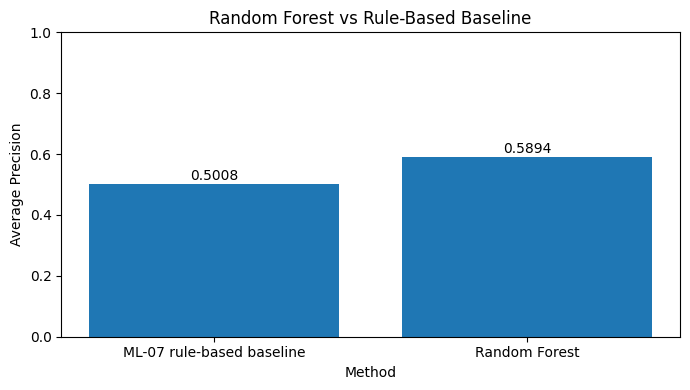

,Measure,Value
0,Training rows,23837.0000
1,Test rows,6163.0000
2,Training clients,25.0000
3,Test clients,7.0000
4,Overlapping clients,0.0000
5,Baseline Average Precision,0.5008
6,Random Forest Average Precision,0.5894


Validation summary saved.


In [8]:
import matplotlib.pyplot as plt

# Use the results calculated in Section 4
plt.figure(figsize=(7, 4))

plt.bar(
    results["Method"],
    results["Average Precision"]
)

plt.title("Random Forest vs Rule-Based Baseline")
plt.ylabel("Average Precision")
plt.xlabel("Method")
plt.ylim(0, 1)

for i, score in enumerate(results["Average Precision"]):
    plt.text(i, score + 0.015, f"{score:.4f}", ha="center")

plt.tight_layout()
plt.savefig("model_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()




# Summarise the validation setup used in Section 4

validation_summary = pd.DataFrame({
    "Measure": [
        "Training rows",
        "Test rows",
        "Training clients",
        "Test clients",
        "Overlapping clients",
        "Baseline Average Precision",
        "Random Forest Average Precision",
    ],
    "Value": [
        len(X_train),
        len(X_test),
        len(train_clients),
        len(test_clients),
        len(train_clients & test_clients),
        round(baseline_ap, 4),
        round(model_ap, 4),
    ],
})

display(validation_summary)

# Save the table for reuse in the research paper
validation_summary.to_csv(
    "validation_summary.csv",
    index=False
)

print("Validation summary saved.")

### What the results show

The Random Forest achieved an Average Precision of 0.5894, compared with 0.5008 for the rule-based baseline. This is an improvement of 0.0886 on the client-grouped test set. The result suggests that the model may be useful for ranking pages with an observed declining trend, but it needs further validation on other clients before being used in practice.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
